In [1]:
# Step 1: Configure the MLflow server and credentials used to track the analysis. Do not commit real passwords.

MLFLOW_SERVER = "http://10.0.100.20:5000"
MLFLOW_USERNAME = "csc-4933-001-user01"
MLFLOW_PASSWORD = "dG7hrCzKxFyJfP9v"

# 1. Hypothesis Revision


### Original Hypothesis

If outdoor temperatures decrease, then hourly electricity demand and estimated grid CO2 emissions will increase because colder conditions can increase electricity use for heating and change the electricity generation mix.

### Reason for Revision

The original hypothesis was designed around hourly weather and electricity grid observations. However, the datasets being used for this analysis contain daily averages for both weather and electricity grid measurements.

To ensure that the analysis uses consistent time intervals, Hypothesis 2 was revised from hourly observations to daily observations. This allows daily average temperatures to be compared with daily average electricity demand and daily estimated grid CO2 emissions.

This revision also means the analysis will focus on broader daily patterns rather than changes occurring within individual hours. As a result, the project will not make conclusions about specific hourly charging or electricity demand patterns.

### Revised Hypothesis

If daily average outdoor temperatures decrease, then daily average electricity demand and daily estimated grid CO2 emissions will increase because colder conditions can increase electricity use for heating and change the electricity generation mix.

### Predictions

The revised hypothesis will be evaluated using two separate predictions:

1. **Electricity Demand:** Days in the coldest daily temperature quartile will have higher average electricity demand than days in the warmest daily temperature quartile.

2. **Grid CO2 Emissions:** Days in the coldest daily temperature quartile will have higher estimated grid CO2 emissions than days in the warmest daily temperature quartile.

These predictions will be evaluated independently because increased electricity demand does not necessarily result in increased carbon emissions. The emissions impact also depends on the types of electricity generation sources being used.


## 2. Load and Inspect the Prepared Daily Data

The input files are:

- combined_daily_averages.csv: daily weather, demand, generation, and recorded-hour measurements.
- fuel_factors_clean.csv: available fuel emissions factors in kg CO2/MWh.

The inspection checks the date range, required columns, missing values, duplicate dates, and recorded hours before the modeling dataset is created.

In [5]:
import os
import getpass
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)

daily_data = pd.read_csv("combined_daily_averages.csv")
fuel_factors_clean = pd.read_csv("fuel_factors_clean.csv")

daily_data["date"] = pd.to_datetime(daily_data["date"])
fuel_factors_clean["fuel"] = (
    fuel_factors_clean["fuel"].astype(str).str.strip().str.lower()
)

print("Daily dataset shape:", daily_data.shape)
print("Fuel-factor dataset shape:", fuel_factors_clean.shape)
print("Date range:", daily_data["date"].min(), "to", daily_data["date"].max())
print("Duplicate dates:", daily_data["date"].duplicated().sum())

display(daily_data.head())
display(fuel_factors_clean)
display(daily_data.isna().sum().rename("missing_values").to_frame())
display(daily_data["hours_recorded"].value_counts().sort_index())

Daily dataset shape: (730, 16)
Fuel-factor dataset shape: (8, 3)
Date range: 2022-01-01 00:00:00 to 2023-12-31 00:00:00
Duplicate dates: 0


,date,demand_mwh,demand_forecast_mwh,net_generation,coal,natural_gas,nuclear,wind,solar,hydro,other,temp_f,heating_degree_hours,wind_speed_mph,relative_humidity,hours_recorded
0,2022-01-01,743.625000,743.958333,743.625000,302.708333,93.333333,210.083333,65.291667,10.458333,51.791667,9.958333,43.691667,21.308333,6.416667,76.625000,24
1,2022-01-02,741.583333,743.333333,741.625000,333.833333,94.583333,209.708333,29.083333,12.083333,52.333333,10.000000,43.258333,21.741667,6.000000,78.333333,24
2,2022-01-03,863.083333,863.875000,862.958333,396.333333,165.291667,210.208333,17.416667,10.625000,53.166667,9.916667,38.054167,26.945833,8.583333,82.166667,24
3,2022-01-04,823.166667,821.541667,823.416667,342.625000,108.000000,210.041667,88.708333,11.916667,52.000000,10.125000,42.395833,22.604167,11.750000,78.250000,24
4,2022-01-05,791.458333,786.625000,791.500000,351.833333,103.208333,210.041667,51.583333,12.250000,52.625000,9.958333,44.670833,20.329167,7.916667,76.916667,24


,fuel,kg_co2_per_mwh,note
0,coal,1010.0,fleet average of the BA's coal units
1,natural_gas,430.0,fleet average of the BA's gas units (combined ...
2,nuclear,0.0,no stack emissions
3,wind,0.0,no stack emissions
4,solar,0.0,no stack emissions
5,hydro,0.0,no stack emissions
6,other,0.0,"landfill gas and biomass; biogenic, counted as..."
7,imports,520.0,average of the neighbouring balancing authorit...


,missing_values
date,0
demand_mwh,0
demand_forecast_mwh,0
net_generation,0
coal,0
natural_gas,0
nuclear,0
wind,0
solar,0
hydro,0


hours_recorded
23      2
24    726
25      2
Name: count, dtype: int64

### 2.1 Inspect daily patterns

These initial visuals show the temperature distribution and the time series of daily average temperature and electricity demand. 

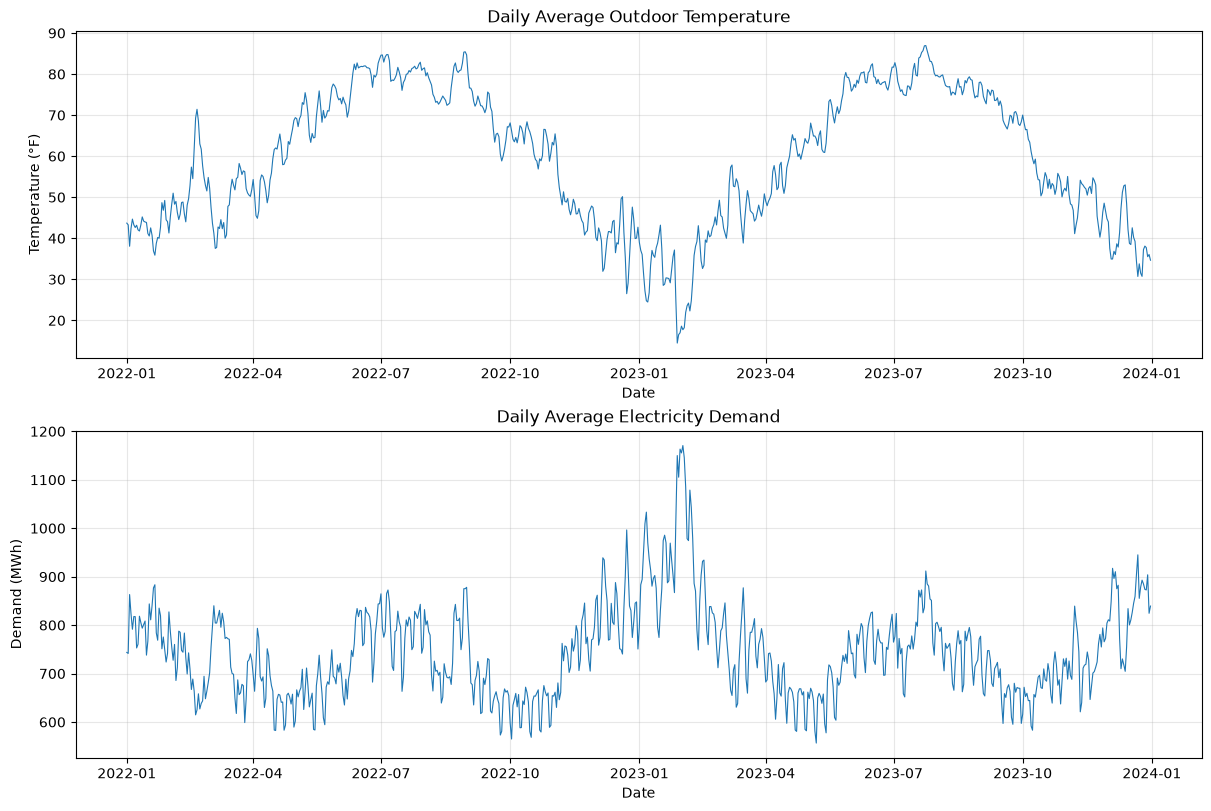

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)

axes[0].plot(daily_data["date"], daily_data["temp_f"], linewidth=0.8)
axes[0].set_title("Daily Average Outdoor Temperature")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Temperature (°F)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(daily_data["date"], daily_data["demand_mwh"], linewidth=0.8)
axes[1].set_title("Daily Average Electricity Demand")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Demand (MWh)")
axes[1].grid(True, alpha=0.3)

plt.show()


## 3. Prepare the Modeling Data and Estimate Daily Grid CO2

### 3.1 Required measurements

The analysis uses date, temp_f, demand_mwh, generation by source, and hours_recorded. Generation values represent daily MWh totals, and demand_mwh represents daily electricity demand. Calendar variables are created for model construction.

### 3.2 Calculate estimated daily grid CO2 emissions
Daily generation totals are multiplied by their corresponding emissions factors (kg_CO2_per_mwh) to estimate CO2 emissions for each generation source. The source-level emissions are then summed to calculate estimated daily grid CO2 emissions.


In [9]:

# Required columns
required_columns = [
    "date", "temp_f", "demand_mwh", "net_generation",
    "coal", "natural_gas", "nuclear", "wind",
    "solar", "hydro", "other", "hours_recorded"
]

missing_columns = [
    c for c in required_columns if c not in daily_data.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")


# Generation categories included in the emissions calculation
generation_fuels = [
    "coal", "natural_gas", "nuclear", "wind",
    "solar", "hydro", "other"
]


# Load emissions factors
emission_factors = (
    fuel_factors_clean
    .drop_duplicates(subset=["fuel"], keep="last")
    .set_index("fuel")["kg_co2_per_mwh"]
    .to_dict()
)


# Sources assumed to have zero operational CO2 emissions
known_zero_emission_fuels = [
    "nuclear", "wind", "solar", "hydro"
]


# Validate emissions factors
for fuel in generation_fuels:

    if fuel in emission_factors:
        factor = emission_factors[fuel]

    elif fuel in known_zero_emission_fuels:
        factor = 0.0

    else:
        raise ValueError(
            f"No emissions factor available for {fuel}. "
            "Verify the source before assigning a value."
        )

    if pd.isna(factor):
        raise ValueError(f"Missing emissions factor for {fuel}.")

    emission_factors[fuel] = float(factor)


# Calculate source-level daily CO2 emissions
for fuel in generation_fuels:

    daily_data[f"{fuel}_CO2_kg"] = (
        daily_data[fuel] * emission_factors[fuel]
    )


# Calculate total daily estimated grid CO2 emissions
emission_columns = [
    f"{fuel}_CO2_kg" for fuel in generation_fuels
]

daily_data["daily_CO2_kg"] = daily_data[emission_columns].sum(
    axis=1,
    min_count=len(emission_columns)
)


# Display calculated results
display(
    daily_data[
        ["date", "demand_mwh", "daily_CO2_kg"]
        + emission_columns
    ].head()
)


print("\nEmissions factors used:")
display(pd.DataFrame(
    list(emission_factors.items()),
    columns=["fuel", "kg_CO2_per_mwh"]
))


,date,demand_mwh,daily_CO2_kg,coal_CO2_kg,natural_gas_CO2_kg,nuclear_CO2_kg,wind_CO2_kg,solar_CO2_kg,hydro_CO2_kg,other_CO2_kg
0,2022-01-01,743.625000,345868.750000,305735.416667,40133.333333,0.0,0.0,0.0,0.0,0.0
1,2022-01-02,741.583333,377842.500000,337171.666667,40670.833333,0.0,0.0,0.0,0.0,0.0
2,2022-01-03,863.083333,471372.083333,400296.666667,71075.416667,0.0,0.0,0.0,0.0,0.0
3,2022-01-04,823.166667,392491.250000,346051.250000,46440.000000,0.0,0.0,0.0,0.0,0.0
4,2022-01-05,791.458333,399731.250000,355351.666667,44379.583333,0.0,0.0,0.0,0.0,0.0



Emissions factors used:


,fuel,kg_CO2_per_mwh
0,coal,1010.0
1,natural_gas,430.0
2,nuclear,0.0
3,wind,0.0
4,solar,0.0
5,hydro,0.0
6,other,0.0
7,imports,520.0


### 3.3 Check generation totals and emissions limitations

The seven available generation categories are compared with net_generation to check how closely the listed sources account for total generation. The dataset does not contain a separate imports generation column, so imported electricity emissions cannot be calculated independently. Estimated emissions therefore represent the available generation categories rather than the complete emissions associated with all electricity supplied to the grid.

Maximum absolute difference between net generation and listed sources: 2.2737367544323206e-13


,date,net_generation,generation_sum,generation_difference
0,2022-01-01,743.625000,743.625000,0.000000e+00
1,2022-01-02,741.625000,741.625000,-1.136868e-13
2,2022-01-03,862.958333,862.958333,1.136868e-13
3,2022-01-04,823.416667,823.416667,0.000000e+00
4,2022-01-05,791.500000,791.500000,0.000000e+00


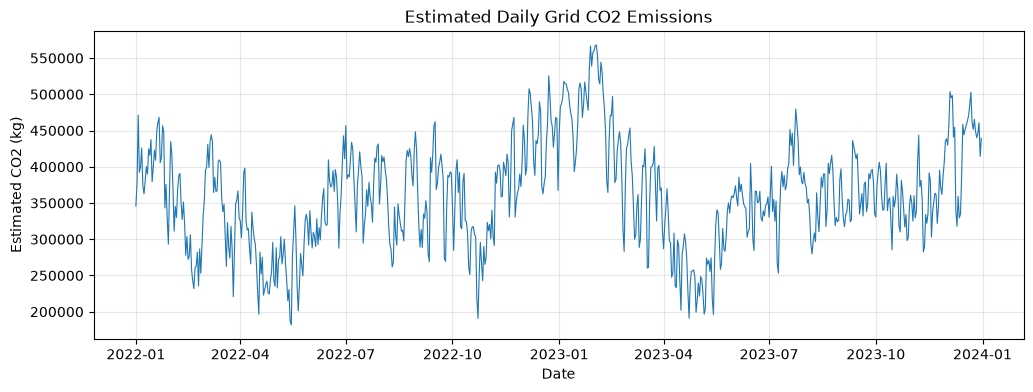

In [10]:
daily_data["generation_sum"] = daily_data[generation_fuels].sum(axis=1)
daily_data["generation_difference"] = (
    daily_data["net_generation"] - daily_data["generation_sum"]
)

print(
    "Maximum absolute difference between net generation and listed sources:",
    daily_data["generation_difference"].abs().max()
)

display(
    daily_data[
        ["date", "net_generation", "generation_sum", "generation_difference"]
    ].head()
)

plt.figure(figsize=(12, 4))
plt.plot(daily_data["date"], daily_data["daily_CO2_kg"], linewidth=0.8)
plt.title("Estimated Daily Grid CO2 Emissions")
plt.xlabel("Date")
plt.ylabel("Estimated CO2 (kg)")
plt.grid(True, alpha=0.3)
plt.show()

### 3.4 Create calendar variables and the modeling dataset

The candidate models use day_of_week and day_of_year as calendar variables. The month and year columns are retained for inspection but are not added to the candidate feature sets, so the model comparisons change one planned feature at a time.

In [12]:
daily_data["day_of_week"] = daily_data["date"].dt.day_of_week
daily_data["day_of_year"] = daily_data["date"].dt.day_of_year
daily_data["month"] = daily_data["date"].dt.month
daily_data["year"] = daily_data["date"].dt.year

model_columns = [
    "date", "temp_f", "demand_mwh", "daily_CO2_kg",
    "day_of_week", "day_of_year", "month", "year"
]

model_data = (
    daily_data[model_columns]
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

print("Modeling observations:", len(model_data))
print("Modeling date range:",
      model_data["date"].min(), "to", model_data["date"].max())
display(model_data.head())

Modeling observations: 730
Modeling date range: 2022-01-01 00:00:00 to 2023-12-31 00:00:00


,date,temp_f,demand_mwh,daily_CO2_kg,day_of_week,day_of_year,month,year
0,2022-01-01,43.691667,743.625000,345868.750000,5,1,1,2022
1,2022-01-02,43.258333,741.583333,377842.500000,6,2,1,2022
2,2022-01-03,38.054167,863.083333,471372.083333,0,3,1,2022
3,2022-01-04,42.395833,823.166667,392491.250000,1,4,1,2022
4,2022-01-05,44.670833,791.458333,399731.250000,2,5,1,2022


## 4. Cold-versus-Warm Experiments

### 4.1 Experiment design

Two outcome comparisons test the two predictions:

- **Experiment A:** daily average electricity demand for cold days versus warm days.
- **Experiment B:** estimated daily grid CO2 emissions for cold days versus warm days.

**Held fixed:** the same prepared daily dataset, date range, temperature thresholds, group definitions, and comparison calculations.

**Varied:** the outcome being measured (demand_mwh or daily_CO2_kg) and, within each comparison, the temperature group (cold versus warm).

The cold group is at or below the 25th percentile of temp_f; the warm group is at or above the 75th percentile. The middle half is excluded. Ties at the thresholds may make group sizes slightly different from exactly 25%.

In [16]:
cold_threshold = model_data["temp_f"].quantile(0.25)
warm_threshold = model_data["temp_f"].quantile(0.75)

model_data["temperature_group"] = np.select(
    [
        model_data["temp_f"] <= cold_threshold,
        model_data["temp_f"] >= warm_threshold
    ],
    ["Cold", "Warm"],
    default="Middle"
)

print(f"Cold threshold (25th percentile): {cold_threshold:.2f} °F")
print(f"Warm threshold (75th percentile): {warm_threshold:.2f} °F")
display(model_data["temperature_group"].value_counts().rename("days").to_frame())

Cold threshold (25th percentile): 45.85 °F
Warm threshold (75th percentile): 74.84 °F


,days
temperature_group,
Middle,364
Cold,183
Warm,183


### 4.2 Compare group means and medians

The absolute difference is cold mean − warm mean. The percentage difference is (cold mean − warm mean) / warm mean × 100. A positive difference means the cold-group average is higher.

In [17]:
def compare_temperature_groups(data, outcome):
    cold = data.loc[data["temperature_group"] == "Cold", outcome].dropna()
    warm = data.loc[data["temperature_group"] == "Warm", outcome].dropna()

    cold_mean = cold.mean()
    warm_mean = warm.mean()
    difference = cold_mean - warm_mean
    percent_difference = (
        difference / warm_mean * 100 if warm_mean != 0 else np.nan
    )

    return {
        "outcome": outcome,
        "cold_n": len(cold),
        "warm_n": len(warm),
        "cold_mean": cold_mean,
        "warm_mean": warm_mean,
        "cold_median": cold.median(),
        "warm_median": warm.median(),
        "cold_minus_warm": difference,
        "percent_difference": percent_difference
    }

experiment_results = pd.DataFrame([
    compare_temperature_groups(model_data, "demand_mwh"),
    compare_temperature_groups(model_data, "daily_CO2_kg")
])

display(experiment_results)

,outcome,cold_n,warm_n,cold_mean,warm_mean,cold_median,warm_median,cold_minus_warm,percent_difference
0,demand_mwh,183,183,851.434595,771.550319,831.458333,772.500000,79.884276,10.353735
1,daily_CO2_kg,183,183,438860.958165,366442.971311,440110.833333,365872.916667,72417.986854,19.762417


### 4.3 Visualizing the comparisons

The scatter plots show the relationship across all daily observations. The boxplots show the distributions in the cold and warm groups used in the experiment.

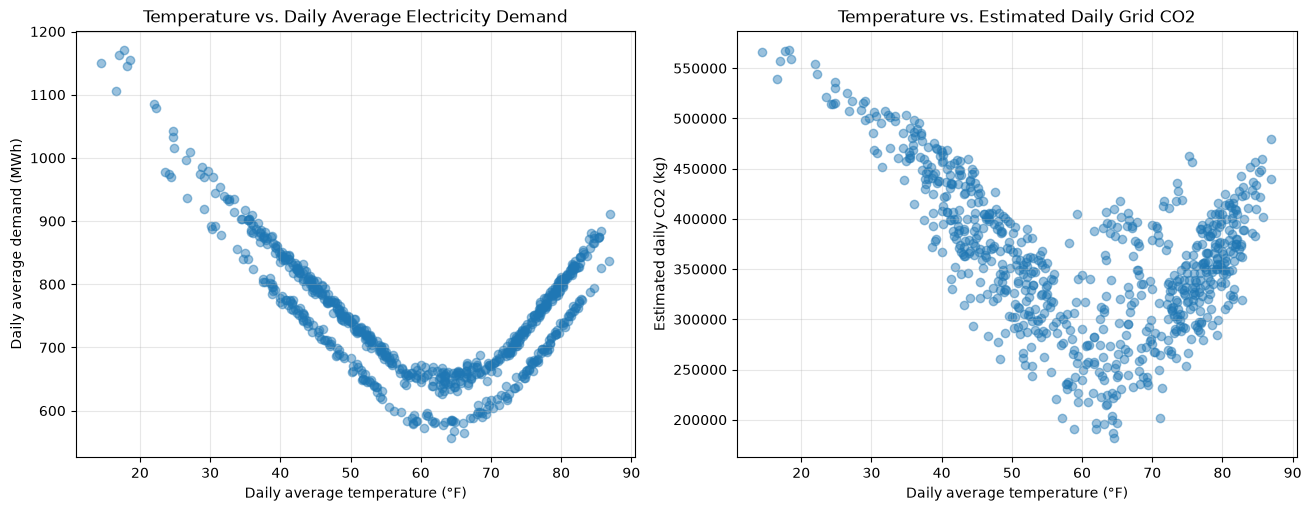

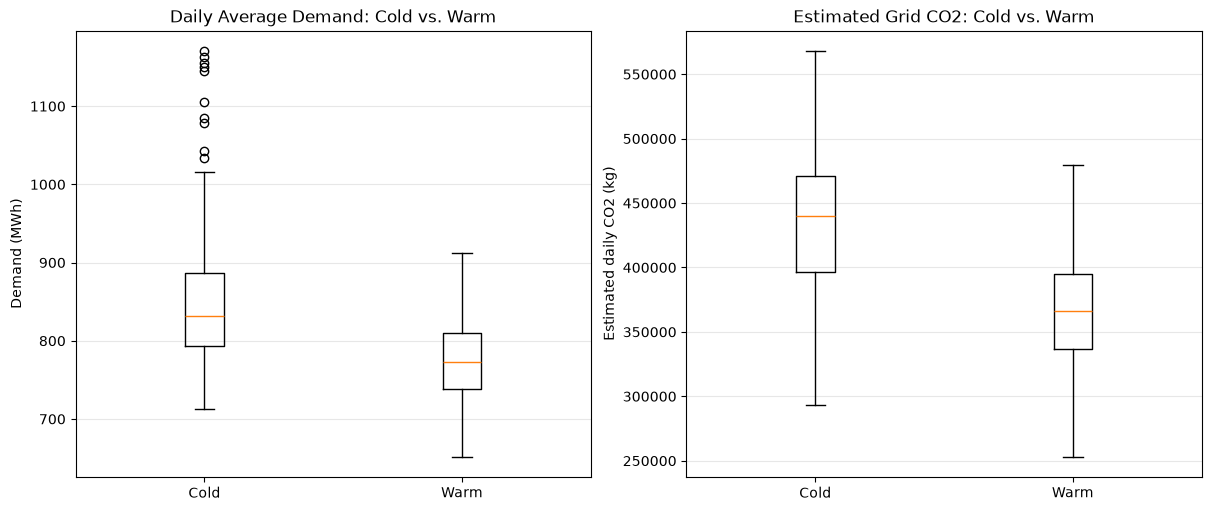

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

axes[0].scatter(model_data["temp_f"], model_data["demand_mwh"], alpha=0.45)
axes[0].set_title("Temperature vs. Daily Average Electricity Demand")
axes[0].set_xlabel("Daily average temperature (°F)")
axes[0].set_ylabel("Daily average demand (MWh)")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(model_data["temp_f"], model_data["daily_CO2_kg"], alpha=0.45)
axes[1].set_title("Temperature vs. Estimated Daily Grid CO2")
axes[1].set_xlabel("Daily average temperature (°F)")
axes[1].set_ylabel("Estimated daily CO2 (kg)")
axes[1].grid(True, alpha=0.3)

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

demand_groups = [
    model_data.loc[model_data["temperature_group"] == group, "demand_mwh"].dropna()
    for group in ["Cold", "Warm"]
]
axes[0].boxplot(demand_groups, tick_labels=["Cold", "Warm"])
axes[0].set_title("Daily Average Demand: Cold vs. Warm")
axes[0].set_ylabel("Demand (MWh)")
axes[0].grid(True, axis="y", alpha=0.3)

emission_groups = [
    model_data.loc[model_data["temperature_group"] == group, "daily_CO2_kg"].dropna()
    for group in ["Cold", "Warm"]
]
axes[1].boxplot(emission_groups, tick_labels=["Cold", "Warm"])
axes[1].set_title("Estimated Grid CO2: Cold vs. Warm")
axes[1].set_ylabel("Estimated daily CO2 (kg)")
axes[1].grid(True, axis="y", alpha=0.3)

plt.show()

## 5.Candidate Models

### 5.1 Model-construction question

The model experiment asks whether daily average temperature adds predictive information beyond calendar variables when predicting:

1. demand_mwh
2. daily_CO2_kg

All candidates use the same Linear Regression algorithm and the same StandardScaler + regression pipeline. The candidate variable sets change in a planned sequence.

### 5.2 Candidate models

| Candidate model | Variables | Reason for inclusion |
|---|---|---|
| **Calendar baseline** | day_of_week, day_of_year | Establishes performance using calendar patterns without temperature. |
| **Calendar + temperature** | Calendar variables + temp_f_centered | Tests whether temperature adds predictive information beyond calendar patterns. |
| **Calendar + temperature + squared temperature** | Calendar variables + temp_f_centered + temp_f_squared | Tests whether a squared temperature term captures a nonlinear pattern. |

The squared term allows a curved temperature relationship. Each candidate adds one feature to the previous feature set, while the algorithm and preprocessing remain unchanged.

### 5.3 Fixed temperature transformation

Temperature is centered at a fixed reference of 65°F. This is a constant, not a statistic estimated from the validation or testing data. It avoids using information from later data when creating the squared term.


In [21]:
TEMP_REFERENCE_F = 65.0

model_data["temp_f_centered"] = model_data["temp_f"] - TEMP_REFERENCE_F
model_data["temp_f_squared"] = model_data["temp_f_centered"] ** 2

feature_sets = {
    "calendar_baseline": [
        "day_of_week",
        "day_of_year"
    ],
    "calendar_temperature": [
        "day_of_week",
        "day_of_year",
        "temp_f_centered"
    ],
    "calendar_temperature_squared": [
        "day_of_week",
        "day_of_year",
        "temp_f_centered",
        "temp_f_squared"
    ]
}

candidate_model_labels = {
    "calendar_baseline": "Calendar baseline",
    "calendar_temperature": "Calendar + temperature",
    "calendar_temperature_squared": "Calendar + temperature + squared temperature"
}

target_variables = {
    "electricity_demand": "demand_mwh",
    "grid_CO2_emissions": "daily_CO2_kg"
}

for model_key, features in feature_sets.items():
    print(candidate_model_labels[model_key], "->", features)

print("\nPrediction targets:", target_variables)

Calendar baseline -> ['day_of_week', 'day_of_year']
Calendar + temperature -> ['day_of_week', 'day_of_year', 'temp_f_centered']
Calendar + temperature + squared temperature -> ['day_of_week', 'day_of_year', 'temp_f_centered', 'temp_f_squared']

Prediction targets: {'electricity_demand': 'demand_mwh', 'grid_CO2_emissions': 'daily_CO2_kg'}


## 6. Shared Chronological Split and Validation Design

### 6.1 One split reused by every candidate

Because the observations are daily and ordered in time, a chronological split is more appropriate than a random split. It simulates predicting later dates from earlier observations and prevents future dates from entering model construction.

The dataset is divided once:

- **Training data:** first 70%; used to fit candidate models.
- **Validation data:** next 15%; used to compare candidates and select a model.
- **Testing data:** final 15%; held back until final testing.

The exact same observations are used for all six candidate runs (three candidate models × two targets).

In [23]:
model_data = model_data.sort_values("date").reset_index(drop=True).copy()

total_rows = len(model_data)
training_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

training_data = model_data.iloc[:training_end].copy()
validation_data = model_data.iloc[training_end:validation_end].copy()
testing_data = model_data.iloc[validation_end:].copy()

split_summary = pd.DataFrame([
    {
        "subset": "Training data",
        "rows": len(training_data),
        "first_date": training_data["date"].min(),
        "last_date": training_data["date"].max()
    },
    {
        "subset": "Validation data",
        "rows": len(validation_data),
        "first_date": validation_data["date"].min(),
        "last_date": validation_data["date"].max()
    },
    {
        "subset": "Testing data",
        "rows": len(testing_data),
        "first_date": testing_data["date"].min(),
        "last_date": testing_data["date"].max()
    }
])

display(split_summary)

assert training_data["date"].max() < validation_data["date"].min()
assert validation_data["date"].max() < testing_data["date"].min()
assert len(training_data) + len(validation_data) + len(testing_data) == len(model_data)

print("Chronological split verified. No dates overlap.")

,subset,rows,first_date,last_date
0,Training data,510,2022-01-01,2023-05-25
1,Validation data,110,2023-05-26,2023-09-12
2,Testing data,110,2023-09-13,2023-12-31


Chronological split verified. No dates overlap.


### 6.2 Time-series cross-validation within training data

Three expanding-window folds are created from **training data only**. Each fold trains on earlier observations and validates on the next chronological block. The validation subset remains the common candidate-selection dataset; the testing subset remains untouched.

In [24]:

time_series_cv = TimeSeriesSplit(n_splits=3)

fold_rows = []
for fold_number, (fold_training_indices, fold_validation_indices) in enumerate(
    time_series_cv.split(training_data), start=1
):
    fold_training = training_data.iloc[fold_training_indices]
    fold_validation = training_data.iloc[fold_validation_indices]

    fold_rows.append({
        "fold": fold_number,
        "training_rows": len(fold_training),
        "training_start": fold_training["date"].min(),
        "training_end": fold_training["date"].max(),
        "validation_rows": len(fold_validation),
        "validation_start": fold_validation["date"].min(),
        "validation_end": fold_validation["date"].max()
    })

display(pd.DataFrame(fold_rows))

,fold,training_rows,training_start,training_end,validation_rows,validation_start,validation_end
0,1,129,2022-01-01,2022-05-09,127,2022-05-10,2022-09-13
1,2,256,2022-01-01,2022-09-13,127,2022-09-14,2023-01-18
2,3,383,2022-01-01,2023-01-18,127,2023-01-19,2023-05-25


### 6.3 Evaluation metrics and interpretation

- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** prediction error that penalizes larger errors more heavily; lower is better.
- **R²:** proportion of target variation explained by the model; values closer to 1 generally indicate a stronger fit, while negative values are possible.

The mean and standard deviation of cross-validation scores describe average performance and variation across chronological folds. The training–validation RMSE gap is validation RMSE minus training RMSE. 

In [25]:

def calculate_metrics(actual, predicted):
    return {
        "mae": mean_absolute_error(actual, predicted),
        "rmse": np.sqrt(mean_squared_error(actual, predicted)),
        "r2": r2_score(actual, predicted)
    }

def build_regression_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

## 7. Model Construction and MLFlow Experiment Tracking

### 7.1 Connect to the shared MLFlow tracking server

AI Usage: Next cell, the code is to help me run this notebook locally, instead of the VM.

In [26]:
# Connect to the provided remote MLflow server
# Configure remote tracking
os.environ["MLFLOW_TRACKING_URI"] = MLFLOW_SERVER
os.environ["MLFLOW_TRACKING_USERNAME"] = MLFLOW_USERNAME
os.environ["MLFLOW_TRACKING_PASSWORD"] = MLFLOW_PASSWORD

mlflow.set_tracking_uri(MLFLOW_SERVER)

# Confirm server access
reply = requests.get(
    MLFLOW_SERVER.rstrip("/") + "/api/2.0/mlflow/experiments/search",
    params={"max_results": 1},
    auth=(MLFLOW_USERNAME, MLFLOW_PASSWORD),
    timeout=10
)

print("Server response:", reply.status_code)

if reply.status_code == 200:
    EXPERIMENT = f"Group1-Climate-Energy-{MLFLOW_USERNAME}"
    mlflow.set_experiment(EXPERIMENT)

    print("Connected successfully!")
    print("Tracking URI:", mlflow.get_tracking_uri())
    print("Experiment:", EXPERIMENT)

elif reply.status_code == 401:
    raise Exception("Incorrect MLflow username or password.")

elif reply.status_code == 403:
    raise Exception("Your account does not have permission to access MLflow.")

else:
    raise Exception(f"MLflow server returned HTTP {reply.status_code}")

Server response: 200
Connected successfully!
Tracking URI: http://10.0.100.20:5000
Experiment: Group1-Climate-Energy-csc-4933-001-user01


In [ ]:
candidate_models = {}
candidate_model_results = []
candidate_run_ids = {}

for target_name, target_column in target_variables.items():
    for feature_name, features in feature_sets.items():

        run_name = f"H2_{target_name}_{feature_name}"

        X_training = training_data[features]
        y_training = training_data[target_column]
        X_validation = validation_data[features]
        y_validation = validation_data[target_column]

        model = build_regression_model()
        model.fit(X_training, y_training)

        training_metrics = calculate_metrics(
            y_training, model.predict(X_training)
        )
        validation_metrics = calculate_metrics(
            y_validation, model.predict(X_validation)
        )

        fold_metric_values = {"mae": [], "rmse": [], "r2": []}
        fold_rmse_values = []

        for fold_number, (fold_train_idx, fold_validation_idx) in enumerate(
            time_series_cv.split(training_data), start=1
        ):
            fold_training = training_data.iloc[fold_train_idx]
            fold_validation = training_data.iloc[fold_validation_idx]

            fold_model = build_regression_model()
            fold_model.fit(
                fold_training[features],
                fold_training[target_column]
            )

            fold_predictions = fold_model.predict(
                fold_validation[features]
            )
            fold_metrics = calculate_metrics(
                fold_validation[target_column],
                fold_predictions
            )

            for metric_name in fold_metric_values:
                fold_metric_values[metric_name].append(
                    fold_metrics[metric_name]
                )
            fold_rmse_values.append(fold_metrics["rmse"])

        cv_summary = {}
        for metric_name, values in fold_metric_values.items():
            cv_summary[f"cv_{metric_name}_mean"] = float(np.mean(values))
            cv_summary[f"cv_{metric_name}_std"] = float(np.std(values, ddof=1))

        training_validation_rmse_gap = (
            validation_metrics["rmse"] - training_metrics["rmse"]
        )

        with mlflow.start_run(run_name=run_name) as active_run:
            mlflow.set_tag("model_stage", "candidate")
            mlflow.set_tag("hypothesis", "H2")
            mlflow.set_tag("experiment_group", EXPERIMENT)
            mlflow.set_tag("candidate_label", candidate_model_labels[feature_name])

            mlflow.log_params({
                "hypothesis": "H2",
                "algorithm": "LinearRegression",
                "target": target_name,
                "target_column": target_column,
                "candidate_model": feature_name,
                "candidate_label": candidate_model_labels[feature_name],
                "features": ", ".join(features),
                "preprocessing": "StandardScaler",
                "data_split": "chronological_70_15_15",
                "cross_validation": "TimeSeriesSplit",
                "cv_folds": 3,
                "temperature_reference_f": TEMP_REFERENCE_F
            })

            for metric_name, value in training_metrics.items():
                mlflow.log_metric(f"training_{metric_name}", float(value))
            for metric_name, value in validation_metrics.items():
                mlflow.log_metric(f"validation_{metric_name}", float(value))
            for metric_name, value in cv_summary.items():
                mlflow.log_metric(metric_name, float(value))

            mlflow.log_metric(
                "training_validation_rmse_gap",
                float(training_validation_rmse_gap)
            )

            for fold_number, fold_rmse in enumerate(fold_rmse_values, start=1):
                mlflow.log_metric(f"cv_fold_{fold_number}_rmse", float(fold_rmse))

            mlflow.log_dict({
                "hypothesis": "H2",
                "target": target_column,
                "candidate_model": feature_name,
                "candidate_label": candidate_model_labels[feature_name],
                "features": features,
                "algorithm": "LinearRegression",
                "preprocessing": "StandardScaler",
                "split": "chronological 70/15/15",
                "cross_validation": "3-fold expanding-window TimeSeriesSplit",
                "temperature_reference_f": TEMP_REFERENCE_F
            }, "experiment_configuration.json")

            mlflow.sklearn.log_model(
                sk_model=model,
                name="model"
            )

            run_id = active_run.info.run_id

        candidate_models[(target_name, feature_name)] = model
        candidate_run_ids[(target_name, feature_name)] = run_id

        candidate_model_results.append({
            "run_name": run_name,
            "run_id": run_id,
            "target": target_name,
            "candidate_model": feature_name,
            "candidate_label": candidate_model_labels[feature_name],
            "features": ", ".join(features),
            "training_mae": training_metrics["mae"],
            "training_rmse": training_metrics["rmse"],
            "training_r2": training_metrics["r2"],
            "validation_mae": validation_metrics["mae"],
            "validation_rmse": validation_metrics["rmse"],
            "validation_r2": validation_metrics["r2"],
            "training_validation_rmse_gap": training_validation_rmse_gap,
            **cv_summary
        })

candidate_model_comparison = pd.DataFrame(candidate_model_results)

print("Candidate runs completed:", len(candidate_model_comparison))
display(candidate_model_comparison.sort_values(
    ["target", "validation_rmse"]
))

2026/11/11 17:53:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run H2_electricity_demand_calendar_baseline at: http://10.0.100.20:5000/#/experiments/128/runs/a577e292124b4394adeeb8f1fd84ff79
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/128


2026/11/11 17:54:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run H2_electricity_demand_calendar_temperature at: http://10.0.100.20:5000/#/experiments/128/runs/c864d3597ba340429595e42e8c5a11d2
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/128


2026/11/11 17:54:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run H2_electricity_demand_calendar_temperature_squared at: http://10.0.100.20:5000/#/experiments/128/runs/13af32d847774fb1a4820187971d2d0c
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/128


... (3 outputs left out)

🏃 View run H2_grid_CO2_emissions_calendar_temperature at: http://10.0.100.20:5000/#/experiments/128/runs/687f5156c5184cc88fa93f02765c4059
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/128


2026/11/11 17:56:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run H2_grid_CO2_emissions_calendar_temperature_squared at: http://10.0.100.20:5000/#/experiments/128/runs/b6909020d98b43e08bf3e89d8e3d39e1
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/128
Candidate runs completed: 6


,run_name,run_id,target,candidate_model,candidate_label,features,training_mae,training_rmse,training_r2,validation_mae,validation_rmse,validation_r2,training_validation_rmse_gap,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std
2,H2_electricity_demand_calendar_temperature_squ...,13af32d847774fb1a4820187971d2d0c,electricity_demand,calendar_temperature_squared,Calendar + temperature + squared temperature,"day_of_week, day_of_year, temp_f_centered, tem...",27.603546,34.672415,0.891640,26.660108,32.903192,0.621049,-1.769223,45.031033,18.774838,60.947928,14.494008,0.514490,0.537097
0,H2_electricity_demand_calendar_baseline,a577e292124b4394adeeb8f1fd84ff79,electricity_demand,calendar_baseline,Calendar baseline,"day_of_week, day_of_year",80.268802,100.720569,0.085599,41.742883,55.245412,-0.068316,-45.475158,128.662177,50.329739,152.792797,48.686763,-2.347464,4.101366
1,H2_electricity_demand_calendar_temperature,c864d3597ba340429595e42e8c5a11d2,electricity_demand,calendar_temperature,Calendar + temperature,"day_of_week, day_of_year, temp_f_centered",69.187433,86.814679,0.320661,89.775429,106.400760,-2.962752,19.586080,125.804178,60.930738,148.347270,60.662412,-2.560605,4.746596
5,H2_grid_CO2_emissions_calendar_temperature_squ...,b6909020d98b43e08bf3e89d8e3d39e1,grid_CO2_emissions,calendar_temperature_squared,Calendar + temperature + squared temperature,"day_of_week, day_of_year, temp_f_centered, tem...",34723.366754,43430.526288,0.709041,29152.794523,35214.120134,0.260451,-8216.406154,54595.211472,9422.086779,70800.036903,7249.581205,0.008929,0.569308
3,H2_grid_CO2_emissions_calendar_baseline,793bb5b4fb7d430b9dfeb8d0bbc22561,grid_CO2_emissions,calendar_baseline,Calendar baseline,"day_of_week, day_of_year",65255.557015,78920.472383,0.039227,31130.690569,40566.585413,0.018545,-38353.886971,108732.755328,46797.109881,124476.445244,48545.154927,-2.966678,4.723554
4,H2_grid_CO2_emissions_calendar_temperature,687f5156c5184cc88fa93f02765c4059,grid_CO2_emissions,calendar_temperature,Calendar + temperature,"day_of_week, day_of_year, temp_f_centered",54420.110282,66040.723291,0.327232,63069.935277,74721.759604,-2.329873,8681.036313,99509.533198,62296.455816,113856.328950,64636.003700,-2.964928,5.504917


### 7.3 Compare candidate model performance

Validation RMSE is the primary selection metric. Cross-validation mean and standard deviation, validation MAE and R², and the training–validation gap provide additional evidence.

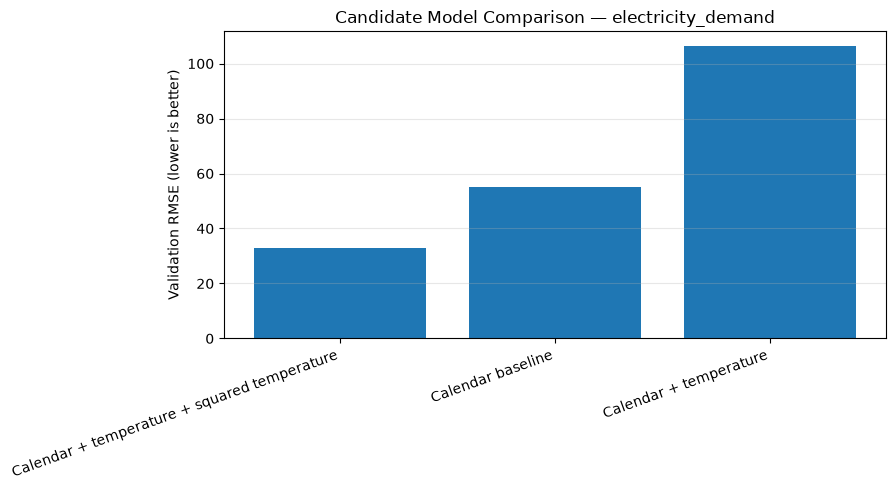

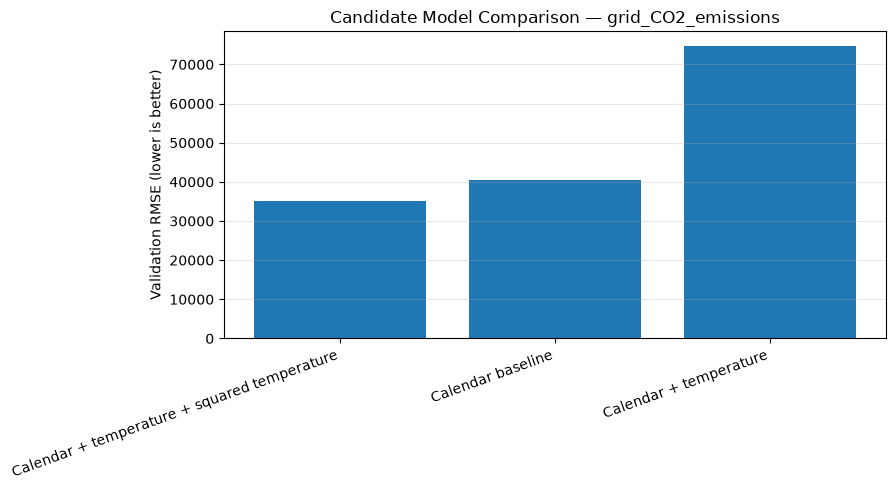

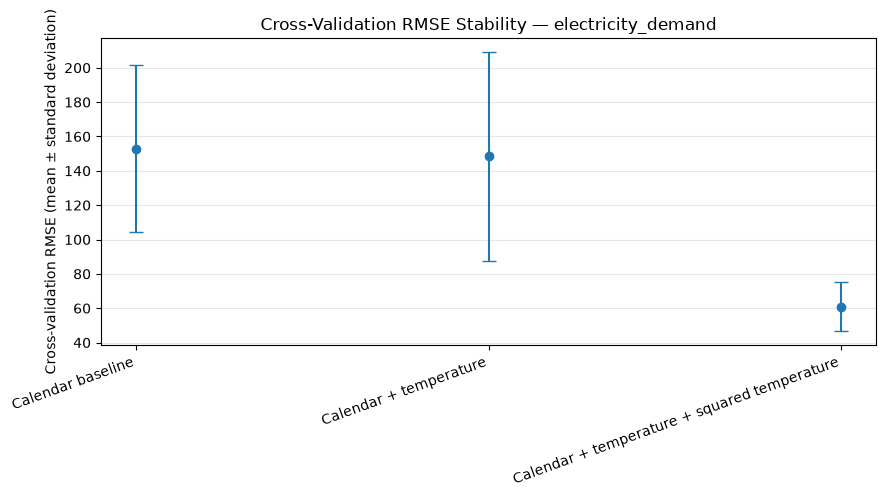

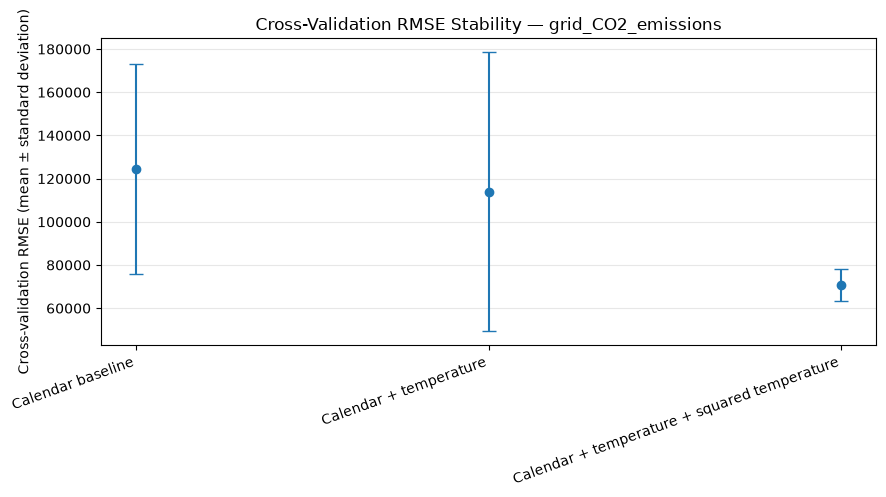

In [28]:
for target_name in target_variables:
    target_results = candidate_model_comparison[
        candidate_model_comparison["target"] == target_name
    ].sort_values("validation_rmse")

    plt.figure(figsize=(9, 5))
    plt.bar(
        target_results["candidate_label"],
        target_results["validation_rmse"]
    )
    plt.title(f"Candidate Model Comparison — {target_name}")
    plt.ylabel("Validation RMSE (lower is better)")
    plt.xticks(rotation=20, ha="right")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# Cross-validation RMSE: mean with one standard deviation
for target_name in target_variables:
    target_results = candidate_model_comparison[
        candidate_model_comparison["target"] == target_name
    ].copy()

    x = np.arange(len(target_results))
    plt.figure(figsize=(9, 5))
    plt.errorbar(
        x,
        target_results["cv_rmse_mean"],
        yerr=target_results["cv_rmse_std"],
        fmt="o",
        capsize=5
    )
    plt.xticks(x, target_results["candidate_label"], rotation=20, ha="right")
    plt.title(f"Cross-Validation RMSE Stability — {target_name}")
    plt.ylabel("Cross-validation RMSE (mean ± standard deviation)")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### 7.4 Select one candidate model per prediction target

For each target, select the candidate with the lowest validation RMSE. Review cross-validation spread and the training–validation gap before accepting the selection. The selection is made without looking at testing-data scores.

In [29]:
selected_candidate_rows = (
    candidate_model_comparison
    .sort_values(["target", "validation_rmse"])
    .groupby("target", as_index=False)
    .first()
)

selected_models = {}
for _, row in selected_candidate_rows.iterrows():
    target_name = row["target"]
    feature_name = row["candidate_model"]
    selected_models[target_name] = {
        "candidate_model": feature_name,
        "candidate_label": candidate_model_labels[feature_name],
        "features": feature_sets[feature_name],
        "model": candidate_models[(target_name, feature_name)],
        "candidate_run_id": row["run_id"]
    }

display(selected_candidate_rows[
    [
        "target", "candidate_label",
        "validation_rmse", "cv_rmse_mean", "cv_rmse_std",
        "training_validation_rmse_gap"
    ]
])

,target,candidate_label,validation_rmse,cv_rmse_mean,cv_rmse_std,training_validation_rmse_gap
0,electricity_demand,Calendar + temperature + squared temperature,32.903192,60.947928,14.494008,-1.769223
1,grid_CO2_emissions,Calendar + temperature + squared temperature,35214.120134,70800.036903,7249.581205,-8216.406154


### 7.5 Retrieve and export the MLflow run table

The exported run table includes the MLflow run name, run ID, all logged parameters, and all logged metrics for the candidate runs.

In [30]:
mlflow_experiment = mlflow.get_experiment_by_name(EXPERIMENT)
if mlflow_experiment is None:
    raise ValueError(
        f"MLflow experiment '{EXPERIMENT}' was not found. "
        "Check the tracking URI and experiment name."
    )

all_experiment_runs = mlflow.search_runs(
    experiment_ids=[mlflow_experiment.experiment_id]
)

candidate_mlflow_runs = all_experiment_runs[
    all_experiment_runs["tags.model_stage"] == "candidate"
].copy()

candidate_mlflow_runs = candidate_mlflow_runs.rename(
    columns={"tags.mlflow.runName": "run_name"}
)

# Keep run identity, all parameter columns, all metric columns, and useful tags.
identity_columns = [
    column for column in [
        "run_name", "run_id", "status", "start_time", "end_time"
    ] if column in candidate_mlflow_runs.columns
]
parameter_columns = sorted(
    column for column in candidate_mlflow_runs.columns
    if column.startswith("params.")
)
metric_columns = sorted(
    column for column in candidate_mlflow_runs.columns
    if column.startswith("metrics.")
)
tag_columns = sorted(
    column for column in candidate_mlflow_runs.columns
    if column.startswith("tags.")
)

mlflow_run_table = candidate_mlflow_runs[
    identity_columns + parameter_columns + metric_columns + tag_columns
].copy()

mlflow_run_table.to_csv("hypothesis_2_mlflow_runs.csv", index=False)

print("Candidate MLflow runs exported:", len(mlflow_run_table))
display(mlflow_run_table)

Candidate MLflow runs exported: 6


,run_name,run_id,status,start_time,end_time,params.algorithm,params.candidate_label,params.candidate_model,params.cross_validation,params.cv_folds,params.data_split,params.features,params.hypothesis,params.preprocessing,params.target,params.target_column,params.temperature_reference_f,metrics.cv_fold_1_rmse,metrics.cv_fold_2_rmse,metrics.cv_fold_3_rmse,metrics.cv_mae_mean,metrics.cv_mae_std,metrics.cv_r2_mean,metrics.cv_r2_std,metrics.cv_rmse_mean,metrics.cv_rmse_std,metrics.training_mae,metrics.training_r2,metrics.training_rmse,metrics.training_validation_rmse_gap,metrics.validation_mae,metrics.validation_r2,metrics.validation_rmse,tags.candidate_label,tags.experiment_group,tags.hypothesis,tags.mlflow.source.name,tags.mlflow.source.type,tags.mlflow.user,tags.model_stage
0,H2_grid_CO2_emissions_calendar_temperature_squ...,b6909020d98b43e08bf3e89d8e3d39e1,FINISHED,2026-11-11 23:56:33.277+00:00,2026-11-11 23:57:10.493+00:00,LinearRegression,Calendar + temperature + squared temperature,calendar_temperature_squared,TimeSeriesSplit,3,chronological_70_15_15,"day_of_week, day_of_year, temp_f_centered, tem...",H2,StandardScaler,grid_CO2_emissions,daily_CO2_kg,65.0,71713.547294,77549.567278,63136.996138,54595.211472,9422.086779,0.008929,0.569308,70800.036903,7249.581205,34723.366754,0.709041,43430.526288,-8216.406154,29152.794523,0.260451,35214.120134,Calendar + temperature + squared temperature,Group1-Climate-Energy-csc-4933-001-user01,H2,Hypothesis2_Experiment.ipynb,NOTEBOOK,csc-4933-001-user01,candidate
1,H2_grid_CO2_emissions_calendar_temperature,687f5156c5184cc88fa93f02765c4059,FINISHED,2026-11-11 23:55:57.626+00:00,2026-11-11 23:56:32.020+00:00,LinearRegression,Calendar + temperature,calendar_temperature,TimeSeriesSplit,3,chronological_70_15_15,"day_of_week, day_of_year, temp_f_centered",H2,StandardScaler,grid_CO2_emissions,daily_CO2_kg,65.0,188346.618025,72584.945534,80637.423292,99509.533198,62296.455816,-2.964928,5.504917,113856.328950,64636.003700,54420.110282,0.327232,66040.723291,8681.036313,63069.935277,-2.329873,74721.759604,Calendar + temperature,Group1-Climate-Energy-csc-4933-001-user01,H2,Hypothesis2_Experiment.ipynb,NOTEBOOK,csc-4933-001-user01,candidate
2,H2_grid_CO2_emissions_calendar_baseline,793bb5b4fb7d430b9dfeb8d0bbc22561,FINISHED,2026-11-11 23:55:19.866+00:00,2026-11-11 23:55:56.416+00:00,LinearRegression,Calendar baseline,calendar_baseline,TimeSeriesSplit,3,chronological_70_15_15,"day_of_week, day_of_year",H2,StandardScaler,grid_CO2_emissions,daily_CO2_kg,65.0,179910.983148,89555.630473,103962.722110,108732.755328,46797.109881,-2.966678,4.723554,124476.445244,48545.154927,65255.557015,0.039227,78920.472383,-38353.886971,31130.690569,0.018545,40566.585413,Calendar baseline,Group1-Climate-Energy-csc-4933-001-user01,H2,Hypothesis2_Experiment.ipynb,NOTEBOOK,csc-4933-001-user01,candidate
3,H2_electricity_demand_calendar_temperature_squ...,13af32d847774fb1a4820187971d2d0c,FINISHED,2026-11-11 23:54:43.582+00:00,2026-11-11 23:55:18.601+00:00,LinearRegression,Calendar + temperature + squared temperature,calendar_temperature_squared,TimeSeriesSplit,3,chronological_70_15_15,"day_of_week, day_of_year, temp_f_centered, tem...",H2,StandardScaler,electricity_demand,demand_mwh,65.0,76.376964,47.617816,58.849004,45.031033,18.774838,0.514490,0.537097,60.947928,14.494008,27.603546,0.891640,34.672415,-1.769223,26.660108,0.621049,32.903192,Calendar + temperature + squared temperature,Group1-Climate-Energy-csc-4933-001-user01,H2,Hypothesis2_Experiment.ipynb,NOTEBOOK,csc-4933-001-user01,candidate
4,H2_electricity_demand_calendar_temperature,c864d3597ba340429595e42e8c5a11d2,FINISHED,2026-11-11 23:54:05.910+00:00,2026-11-11 23:54:42.412+00:00,LinearRegression,Calendar + temperature,calendar_temperature,TimeSeriesSplit,3,chronological_70_15_15,"day_of_week, day_of_year, temp_f_centered",H2,StandardScaler,electricity_demand,demand_mwh,65.0,218.365541,111.603346,115.072922,125.804178,60.930738,-2.560605,4.746596,148.347270,60.662412,69.1

## 8. Model Selection, Validation, and Testing

### 8.1 Validation evidence for the selected models

For each selected candidate, report:
- validation MAE, RMSE, and R²;
- cross-validation RMSE mean and standard deviation;
- training–validation RMSE gap.

The validation data was not used to fit the candidate model. The cross-validation folds use training data only and provide evidence about performance stability across earlier time periods.

In [31]:
validation_evidence = selected_candidate_rows[
    [
        "target", "candidate_label",
        "training_rmse", "validation_rmse",
        "validation_mae", "validation_r2",
        "cv_rmse_mean", "cv_rmse_std",
        "training_validation_rmse_gap"
    ]
].copy()

display(validation_evidence)

,target,candidate_label,training_rmse,validation_rmse,validation_mae,validation_r2,cv_rmse_mean,cv_rmse_std,training_validation_rmse_gap
0,electricity_demand,Calendar + temperature + squared temperature,34.672415,32.903192,26.660108,0.621049,60.947928,14.494008,-1.769223
1,grid_CO2_emissions,Calendar + temperature + squared temperature,43430.526288,35214.120134,29152.794523,0.260451,70800.036903,7249.581205,-8216.406154


### 8.2 Final model construction and one-time testing

After model selection, each selected model is refitted using the combined training and validation data. The reserved testing data is then scored once for each target. No feature selection or tuning is performed using the testing results.

In [32]:
development_data = pd.concat(
    [training_data, validation_data],
    ignore_index=True
)

final_models = {}
final_test_rows = []
test_predictions_by_target = {}

for target_name, selection in selected_models.items():
    target_column = target_variables[target_name]
    features = selection["features"]

    final_model = build_regression_model()
    final_model.fit(
        development_data[features],
        development_data[target_column]
    )

    # The reserved testing subset is evaluated once here.
    predictions = final_model.predict(testing_data[features])
    test_metrics = calculate_metrics(
        testing_data[target_column],
        predictions
    )

    final_models[target_name] = final_model
    test_predictions_by_target[target_name] = predictions

    final_test_rows.append({
        "target": target_name,
        "selected_candidate_model": selection["candidate_model"],
        "selected_candidate_label": selection["candidate_label"],
        "test_mae": test_metrics["mae"],
        "test_rmse": test_metrics["rmse"],
        "test_r2": test_metrics["r2"]
    })

    with mlflow.start_run(
        run_name=f"FINAL_TEST_{target_name}_{selection['candidate_model']}"
    ) as final_run:
        mlflow.set_tag("model_stage", "final_test")
        mlflow.set_tag("hypothesis", "H2")
        mlflow.log_params({
            "algorithm": "LinearRegression",
            "target": target_name,
            "selected_candidate_model": selection["candidate_model"],
            "features": ", ".join(features),
            "training_data": "training_plus_validation",
            "testing_data": "reserved_chronological_final_15_percent"
        })
        for metric_name, value in test_metrics.items():
            mlflow.log_metric(f"test_{metric_name}", float(value))
        mlflow.sklearn.log_model(
            sk_model=final_model,
            name="final_model"
        )

final_test_results = pd.DataFrame(final_test_rows)
display(final_test_results)

🏃 View run FINAL_TEST_electricity_demand_calendar_temperature_squared at: http://10.0.100.20:5000/#/experiments/128/runs/a2376095cd984b37b3c9f822badeab28
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/128
🏃 View run FINAL_TEST_grid_CO2_emissions_calendar_temperature_squared at: http://10.0.100.20:5000/#/experiments/128/runs/6a6260e8fb6f4a25a23181ffcc14169d
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/128


,target,selected_candidate_model,selected_candidate_label,test_mae,test_rmse,test_r2
0,electricity_demand,calendar_temperature_squared,Calendar + temperature + squared temperature,23.566209,29.866920,0.881041
1,grid_CO2_emissions,calendar_temperature_squared,Calendar + temperature + squared temperature,28952.344168,36302.464239,0.528954


### 8.3 Visualize final testing performance

The first chart compares actual and predicted values on the reserved testing dates. The second chart shows the actual minus predicted. These visuals help identify systematic errors or unusually large prediction errors.

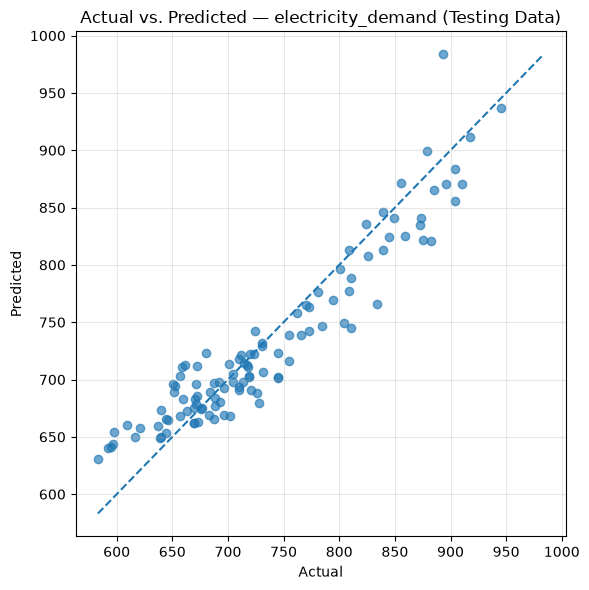

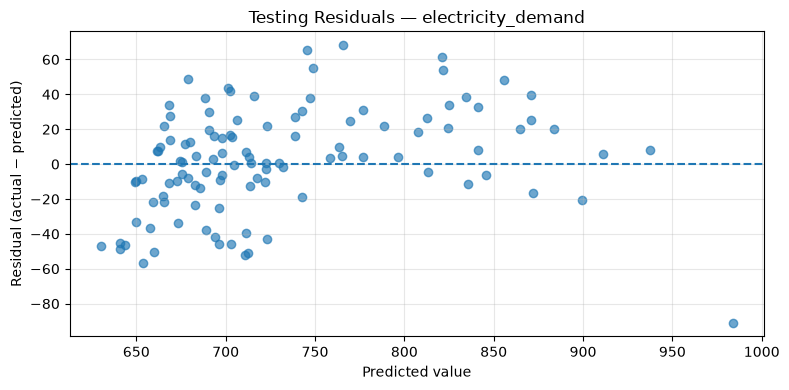

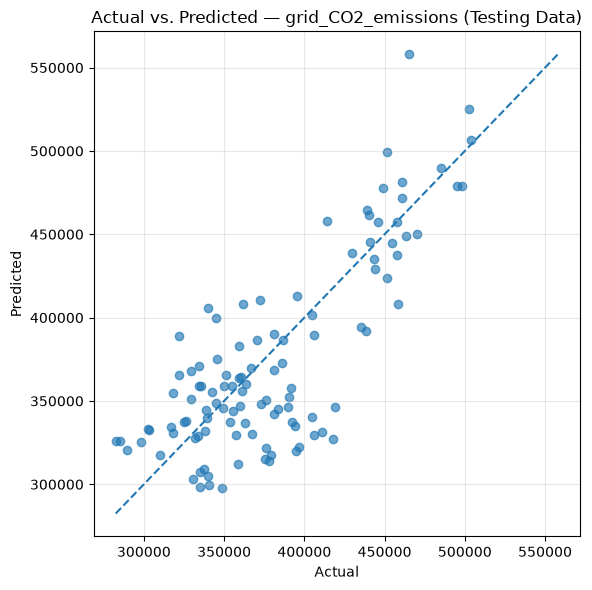

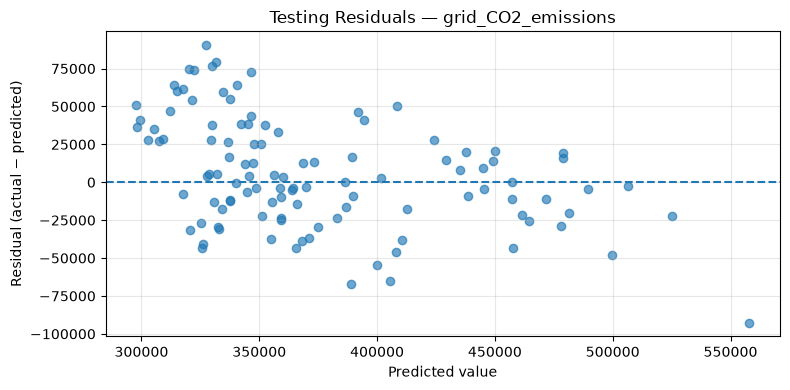

In [33]:
for target_name, target_column in target_variables.items():
    actual = testing_data[target_column].to_numpy()
    predicted = test_predictions_by_target[target_name]
    residuals = actual - predicted

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    plt.figure(figsize=(6, 6))
    plt.scatter(actual, predicted, alpha=0.65)
    plt.plot([lower, upper], [lower, upper], linestyle="--")
    plt.title(f"Actual vs. Predicted — {target_name} (Testing Data)")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.scatter(predicted, residuals, alpha=0.65)
    plt.axhline(0, linestyle="--")
    plt.title(f"Testing Residuals — {target_name}")
    plt.xlabel("Predicted value")
    plt.ylabel("Residual (actual − predicted)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### 8.4 Compare validation and testing scores

In [34]:
validation_test_comparison = selected_candidate_rows[
    ["target", "candidate_label", "validation_rmse"]
].merge(
    final_test_results[["target", "test_mae", "test_rmse", "test_r2"]],
    on="target",
    how="left"
)

validation_test_comparison["test_minus_validation_rmse"] = (
    validation_test_comparison["test_rmse"]
    - validation_test_comparison["validation_rmse"]
)

display(validation_test_comparison)

,target,candidate_label,validation_rmse,test_mae,test_rmse,test_r2,test_minus_validation_rmse
0,electricity_demand,Calendar + temperature + squared temperature,32.903192,23.566209,29.866920,0.881041,-3.036271
1,grid_CO2_emissions,Calendar + temperature + squared temperature,35214.120134,28952.344168,36302.464239,0.528954,1088.344105


### 8.5 Hypothesis Verdicts

The cold-versus-warm experiments determine the hypothesis verdict. Model scores provide additional predictive context, but predictive performance alone does not prove that temperature caused changes in demand or emissions.

For each prediction:
- **Supported:** the cold-minus-warm 95% interval is entirely above zero.
- **Rejected:** the interval is entirely below zero.
- **Unresolved:** the interval includes zero.

The original hourly hypothesis was **revised** to a daily hypothesis because of the temporal resolution of the prepared data. That revision is documented in Section 1; the evidence verdict below applies to the revised daily hypothesis.

In [37]:
def prediction_verdict(cold_minus_warm):
    if cold_minus_warm > 0:
        return "Supported"
    elif cold_minus_warm < 0:
        return "Rejected"
    else:
        return "No observed difference"

verdict_rows = []

for _, row in experiment_results.iterrows():
    verdict_rows.append({
        "prediction": row["outcome"],
        "cold_minus_warm": row["cold_minus_warm"],
        "percent_difference": row["percent_difference"],
        "verdict": prediction_verdict(row["cold_minus_warm"])
    })

prediction_verdicts = pd.DataFrame(verdict_rows)

display(prediction_verdicts)

verdict_set = set(prediction_verdicts["verdict"])
if verdict_set == {"Supported"}:
    overall_hypothesis_verdict = "Supported"
elif verdict_set == {"Rejected"}:
    overall_hypothesis_verdict = "Rejected"
else:
    overall_hypothesis_verdict = "Unresolved"

print("Overall verdict for revised daily Hypothesis 2:",
      overall_hypothesis_verdict)

,prediction,cold_minus_warm,percent_difference,verdict
0,demand_mwh,79.884276,10.353735,Supported
1,daily_CO2_kg,72417.986854,19.762417,Supported


Overall verdict for revised daily Hypothesis 2: Supported


### 8.6 Export the M2 Evidence

The following files preserve the numerical evidence required for the repository:
- `hypothesis_2_mlflow_runs.csv`: MLflow run name, run ID, parameters, metrics, and tags.
- `hypothesis_2_cold_warm_results.csv`: cold-versus-warm means, medians, counts, and differences.
- `hypothesis_2_candidate_model_comparison.csv`: candidate model validation and cross-validation results.
- `hypothesis_2_final_test_results.csv`: one-time final testing results.
- `hypothesis_2_validation_test_comparison.csv`: validation versus testing scores.
- `hypothesis_2_verdicts.csv`: prediction-level and overall verdict evidence.

In [36]:
mlflow_run_table.to_csv("hypothesis_2_mlflow_runs.csv", index=False)
experiment_results.to_csv(
    "hypothesis_2_cold_warm_results.csv", index=False
)

candidate_model_comparison.to_csv(
    "hypothesis_2_candidate_model_comparison.csv", index=False
)
final_test_results.to_csv(
    "hypothesis_2_final_test_results.csv", index=False
)
validation_test_comparison.to_csv(
    "hypothesis_2_validation_test_comparison.csv", index=False
)
prediction_verdicts.to_csv(
    "hypothesis_2_verdicts.csv", index=False
)

print("M2 evidence files exported.")

M2 evidence files exported.
